# HW 7, Problem 3: Stochastic ensemble Kalman filter on Lorenz–63

## Setup

* **Model and truth.** Lorenz–63 with the standard parameters ($\sigma = 10$, $\rho = 28$, $\beta = 8/3$), started from the spun-up HW 1 state (`data/lorenz63_ic.npy`). `hw5.load_model` loads both, plus the long-run covariance $B$ saved in HW 5 (`data/climatology_lorenz63.json`).
* **Observations.** Every $\delta t = 0.1$ on $[0, 10]$, at $t_k = k\,\delta t$ for $k = 1, \dots, L = 100$ (none at $t_0$). Full-state data $y_k = x_k^\dagger + v_k$, $v_k \sim N(0, I_3)$.
* **Forecast.** Every member is advanced between observation times by the same deterministic solver as the truth (`solve_ivp`, RK45, `rtol = atol = 1e-9`), sampled at 10 sub-steps per window for plotting. $Q_k = 0$; no inflation, no localization.
* **Initial ensemble.** $D = \operatorname{diag}(\sqrt{B_{11}}, \sqrt{B_{22}}, \sqrt{B_{33}})$, $m_0^a = x_0^\dagger + 0.2D(1, 1, 1)^T$, $P_0^a = 0.04D^2$; members drawn independently from $N(m_0^a, P_0^a)$. $B$ is used only here.
* **Analysis** (`src/da_models/enkf.py`):
$$K_{k,e} = P^f_{k,e}H^T\big(HP^f_{k,e}H^T + R\big)^{-1}, \qquad x_k^{a,(i)} = x_k^{f,(i)} + K_{k,e}\big(y_k + v_k^{(i)} - Hx_k^{f,(i)}\big), \qquad v_k^{(i)} \sim N(0, R),$$
  with $P^f_{k,e}$ the sample covariance (normalized by $N_e - 1$) and $K_{k,e}$ obtained by solving $S\,K_{k,e}^T = HP^f_{k,e}$, $S = HP^f_{k,e}H^T + R$. The analysis mean $\bar x_k^a$ and covariance $P^a_{k,e}$ are recomputed from the updated members.
* **Random streams** (three separate generators): data `default_rng(513)`; initial members for ensemble size $N_e$ and replicate $r$: `default_rng([513, 1, Ne, r])`; observation perturbations: `default_rng([513, 2, Ne, r])`, with $r \in \{0, 1, 2\}$.
* **Errors.** As in Problem 2 with $n = 3$: $\mathrm{RMSE}_k = \sqrt{\tfrac13\lVert \bar x_k^a - x_k^\dagger\rVert_2^2}$, $\mathrm{Spread}_k = \sqrt{\tfrac13\operatorname{tr}P^a_{k,e}}$, and the time average $\sqrt{L^{-1}\sum_{k=1}^{L}\mathrm{RMSE}_k^2}$.
* **Runtime.** By default all members go through one `solve_ivp` call per window (members are independent, so this is the same ODE with shared adaptive steps). The table also times a member-by-member loop with the same seeds.

In [2]:
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from da_models import hw5
from da_models import damped_oscillator as osc
from da_models.assimilation import make_propagator, simulate_truth, selection_operator, flatten
from da_models.enkf import make_ensemble_propagator, draw_initial_ensemble, run_enkf
from da_models.kalman import run_kf, rmse_and_spread

DATA_DIR = "../data"   # adjust if running in Colab

# ---- settings ----
DT_OBS = 0.1                  # time between observations
T_FINAL = 10.0                # assimilate on [0, T_FINAL]
N_SUB = 10                    # plotting sub-steps per window
L = int(round(T_FINAL / DT_OBS))
ENSEMBLE_SIZES = (10, 50)
REPLICATES = (0, 1, 2)
SEED = 513
REPEATS = 3                   # timing: best of REPEATS for the stacked solver

def rng_init(Ne, r):          # initial members
    return np.random.default_rng([SEED, 1, Ne, r])

def rng_pert(Ne, r):          # observation perturbations
    return np.random.default_rng([SEED, 2, Ne, r])

model = hw5.load_model("lorenz63", DATA_DIR)
params, B, labels = model["params"], model["B"], model["labels"]
x0_true = model["x_true0"]
n = x0_true.size

D = np.diag(np.sqrt(np.diag(B)))
m0 = x0_true + 0.2 * D @ np.ones(n)
P0 = 0.04 * D @ D

propagate_truth = make_propagator(model["rhs"], params, DT_OBS, N_SUB)
propagate_ens = make_ensemble_propagator(model["rhs"], params, DT_OBS, N_SUB)
propagate_ens_loop = make_ensemble_propagator(model["rhs"], params, DT_OBS, N_SUB, vectorized=False)

t_obs = DT_OBS * np.arange(1, L + 1)      # t_1, ..., t_L
t_an = DT_OBS * np.arange(L + 1)          # t_0, ..., t_L

np.set_printoptions(precision=4, suppress=True)
print("parameters:", params)
print("x0_true   :", x0_true)
print("sqrt(diag B):", np.diag(D))
print("m0^a      :", m0)
print("diag P0^a :", np.diag(P0))

C = dict(truth="#0b0b0b", mean="#2a78d6", band="#2a78d6", free="#8c8a85", obs="#eb6834")
REP_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]      # replicates r = 0, 1, 2 (fixed order)
plt.rcParams.update({
    "axes.grid": True, "grid.color": "0.9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 1.2, "legend.frameon": False, "figure.dpi": 110,
})

def time_avg_rmse(rmse):
    # sqrt( L^{-1} sum_{k=1}^{L} RMSE_k^2 ); rmse[0] is the initial time and is excluded
    return np.sqrt(np.mean(rmse[1:] ** 2))

parameters: {'sigma': 10.0, 'rho': 28.0, 'beta': 2.6666666666666665}
x0_true   : [ 2.4996  2.5574 19.7466]
sqrt(diag B): [7.9244 9.0078 8.6141]
m0^a      : [ 4.0845  4.359  21.4694]
diag P0^a : [2.5118 3.2456 2.9681]


## Checks

1. The stacked (vectorized) ensemble propagator matches a member-by-member loop.
2. With a **linear** model and a large ensemble, the EnKF should approach the Kalman filter from Problem 2. Here: the damped oscillator from Problem 2, observed every 0.1 time units (100 Euler steps per window, so $M_{\text{window}} = M^{100}$), $H = [1\ 0]$, $R = 5$, 20 analyses. The table shows the largest difference from `run_kf` at the last analysis as $N_e$ grows.

In [3]:
E_test = draw_initial_ensemble(m0, P0, 10, np.random.default_rng(0))
print("stacked vs loop propagator, max |difference|:",
      f"{np.abs(propagate_ens(E_test) - propagate_ens_loop(E_test)).max():.1e}")

M_win = np.linalg.matrix_power(osc.euler_matrix(1.0, 1e-3, 1e-3), 100)
H_lin, R_lin = np.array([[1.0, 0.0]]), np.array([[5.0]])
x_lin = [np.array([1.0, 2.0])]
for _ in range(20):
    x_lin.append(M_win @ x_lin[-1])
x_lin = np.array(x_lin)
Y_lin = x_lin[1:, :1] + np.sqrt(5.0) * np.random.default_rng(1).standard_normal((20, 1))

kf_lin = run_kf(M_win, H_lin, R_lin, Y_lin, np.zeros(2), np.eye(2))
propagate_lin = lambda E: np.stack([E, M_win @ E])     # (n_sub+1 = 2, n, Ne)

print(f"\n{'Ne':>8} {'max |mean_EnKF - m_KF|':>24} {'max |P_EnKF - P_KF|':>22}   (max |P_KF| = {np.abs(kf_lin['P_a'][-1]).max():.3f})")
for Ne in [100, 1_000, 10_000, 100_000]:
    E0 = draw_initial_ensemble(np.zeros(2), np.eye(2), Ne, np.random.default_rng(2))
    en = run_enkf(propagate_lin, E0, Y_lin, H_lin, R_lin, np.random.default_rng(3))
    print(f"{Ne:>8} {np.abs(en['mean_a'][-1] - kf_lin['m_a'][-1]).max():>24.4f} "
          f"{np.abs(en['cov_a'][-1] - kf_lin['P_a'][-1]).max():>22.4f}")

stacked vs loop propagator, max |difference|: 2.3e-09

      Ne   max |mean_EnKF - m_KF|    max |P_EnKF - P_KF|   (max |P_KF| = 0.403)
     100                   0.0644                 0.0881
    1000                   0.0455                 0.0071
   10000                   0.0178                 0.0066
  100000                   0.0017                 0.0040


## (a) Truth, observations, and free forecast

One truth trajectory from $x_0^\dagger$, full-state observations $y_k = x_k^\dagger + v_k$ with $v_k \sim N(0, I_3)$ from the data stream, and a free forecast: the model run from $m_0^a$ with no assimilation.

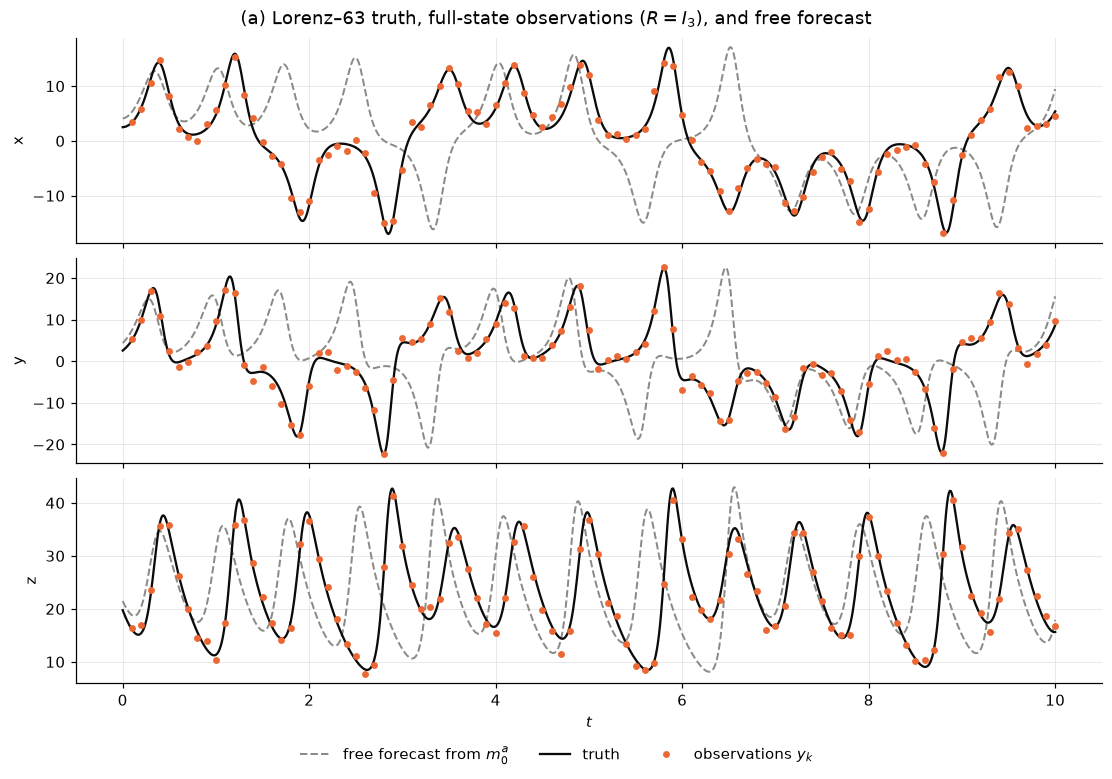

free forecast: time-averaged RMSE 11.170, final RMSE 4.805


In [4]:
rng_data = np.random.default_rng(SEED)
truth = simulate_truth(propagate_truth, x0_true, L)          # (L, N_SUB+1, 3) windows
x_true = np.vstack([x0_true, truth[:, -1]])                  # x_k^dagger at t_0..t_L
Y_full = x_true[1:] + rng_data.standard_normal((L, n))       # Y_full[k-1] = y_k

free = simulate_truth(propagate_truth, m0, L)
x_free = np.vstack([m0, free[:, -1]])
rmse_free = np.sqrt(np.sum((x_free - x_true) ** 2, axis=1) / n)

t_tr, X_tr = flatten(truth, DT_OBS)
t_fr, X_fr = flatten(free, DT_OBS)

fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True, constrained_layout=True)
for i, ax in enumerate(axes):
    ax.plot(t_fr, X_fr[:, i], color=C["free"], ls="--", lw=1.3, label=r"free forecast from $m_0^a$")
    ax.plot(t_tr, X_tr[:, i], color=C["truth"], lw=1.5, label="truth")
    ax.plot(t_obs, Y_full[:, i], "o", ms=3.5, color=C["obs"], label="observations $y_k$")
    ax.set_ylabel(labels[i])
axes[-1].set_xlabel("$t$")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=3)
fig.suptitle(r"(a) Lorenz–63 truth, full-state observations ($R = I_3$), and free forecast")
plt.show()

print(f"free forecast: time-averaged RMSE {time_avg_rmse(rmse_free):.3f}, final RMSE {rmse_free[-1]:.3f}")

## (b) Observing $x$ and $y$ only

$H = \begin{pmatrix} 1 & 0 & 0 \\ 0 & 1 & 0 \end{pmatrix}$, $R = I_2$: the first two components of the same data from (a). $N_e = 10$ and $50$, three replicates each (independent initial-ensemble and perturbation seeds). Truth and data are the same for every run.

In [5]:
H_part = selection_operator(n, [0, 1])
R_part = np.eye(2)
Y_part = Y_full[:, :2]

def timed_enkf(propagate, E0, Y, H, R, Ne, r, repeats):
    # Best wall time of `repeats` runs; every repeat uses a fresh copy of the same
    # perturbation stream, so all repeats give identical results.
    best = None
    for _ in range(repeats):
        out = run_enkf(propagate, E0, Y, H, R, rng_pert(Ne, r))
        if best is None or out["wall_time"] < best["wall_time"]:
            best = out
    best["rmse"], best["spread"] = rmse_and_spread(best["mean_a"], best["cov_a"], x_true)
    return best

runs = {}    # (Ne, r) -> result
for Ne in ENSEMBLE_SIZES:
    for r in REPLICATES:
        E0 = draw_initial_ensemble(m0, P0, Ne, rng_init(Ne, r))
        out = timed_enkf(propagate_ens, E0, Y_part, H_part, R_part, Ne, r, REPEATS)
        loop = run_enkf(propagate_ens_loop, E0, Y_part, H_part, R_part, rng_pert(Ne, r))
        out["wall_time_loop"] = loop["wall_time"]
        out["loop_max_diff"] = np.abs(loop["mean_a"] - out["mean_a"]).max()
        runs[(Ne, r)] = out

header = (f"{'run':<22} {'sqrt(mean RMSE^2)':>18} {'final RMSE':>11} {'sqrt(mean spread^2)':>20} "
          f"{'runtime (s)':>12} {'loop runtime (s)':>17}")
print(header); print("-" * len(header))
for Ne in ENSEMBLE_SIZES:
    for r in REPLICATES:
        o = runs[(Ne, r)]
        print(f"{f'Ne = {Ne}, r = {r}':<22} {time_avg_rmse(o['rmse']):>18.3f} {o['rmse'][-1]:>11.3f} "
              f"{time_avg_rmse(o['spread']):>20.3f} {o['wall_time']:>12.3f} {o['wall_time_loop']:>17.2f}")
    avg = np.array([time_avg_rmse(runs[(Ne, r)]["rmse"]) for r in REPLICATES])
    fin = np.array([runs[(Ne, r)]["rmse"][-1] for r in REPLICATES])
    print(f"{f'Ne = {Ne}, mean ± sd':<22} {f'{avg.mean():.3f} ± {avg.std(ddof=1):.3f}':>18} "
          f"{f'{fin.mean():.3f} ± {fin.std(ddof=1):.3f}':>11}")
    print("-" * len(header))
print(f"{'free forecast':<22} {time_avg_rmse(rmse_free):>18.3f} {rmse_free[-1]:>11.3f}")
print(f"\nlargest |mean difference| between the stacked and looped runs: "
      f"{max(o['loop_max_diff'] for o in runs.values()):.1e}")

# representative run for each Ne: the replicate with the median time-averaged RMSE
rep = {}
for Ne in ENSEMBLE_SIZES:
    order = sorted(REPLICATES, key=lambda r: time_avg_rmse(runs[(Ne, r)]["rmse"]))
    rep[Ne] = order[len(order) // 2]
print("representative (median) replicate:", {f"Ne = {Ne}": f"r = {r}" for Ne, r in rep.items()})

run                     sqrt(mean RMSE^2)  final RMSE  sqrt(mean spread^2)  runtime (s)  loop runtime (s)
---------------------------------------------------------------------------------------------------------
Ne = 10, r = 0                      0.315       0.146                0.391        0.083              0.56
Ne = 10, r = 1                      0.351       0.270                0.365        0.084              0.49
Ne = 10, r = 2                      1.222       0.079                0.374        0.084              0.49
Ne = 10, mean ± sd          0.629 ± 0.514 0.165 ± 0.097
---------------------------------------------------------------------------------------------------------
Ne = 50, r = 0                      0.355       0.295                0.439        0.100              2.50
Ne = 50, r = 1                      0.349       0.363                0.416        0.103              2.55
Ne = 50, r = 2                      0.373       0.196                0.422        0.106         

### Representative runs

For each $N_e$, the replicate with the median time-averaged RMSE. Rows: one observed coordinate (set `OBS_COORD`) and the hidden $z$. The shaded band is $\bar x \pm 2$ ensemble standard deviations; vertical strokes in the mean are the analysis updates.

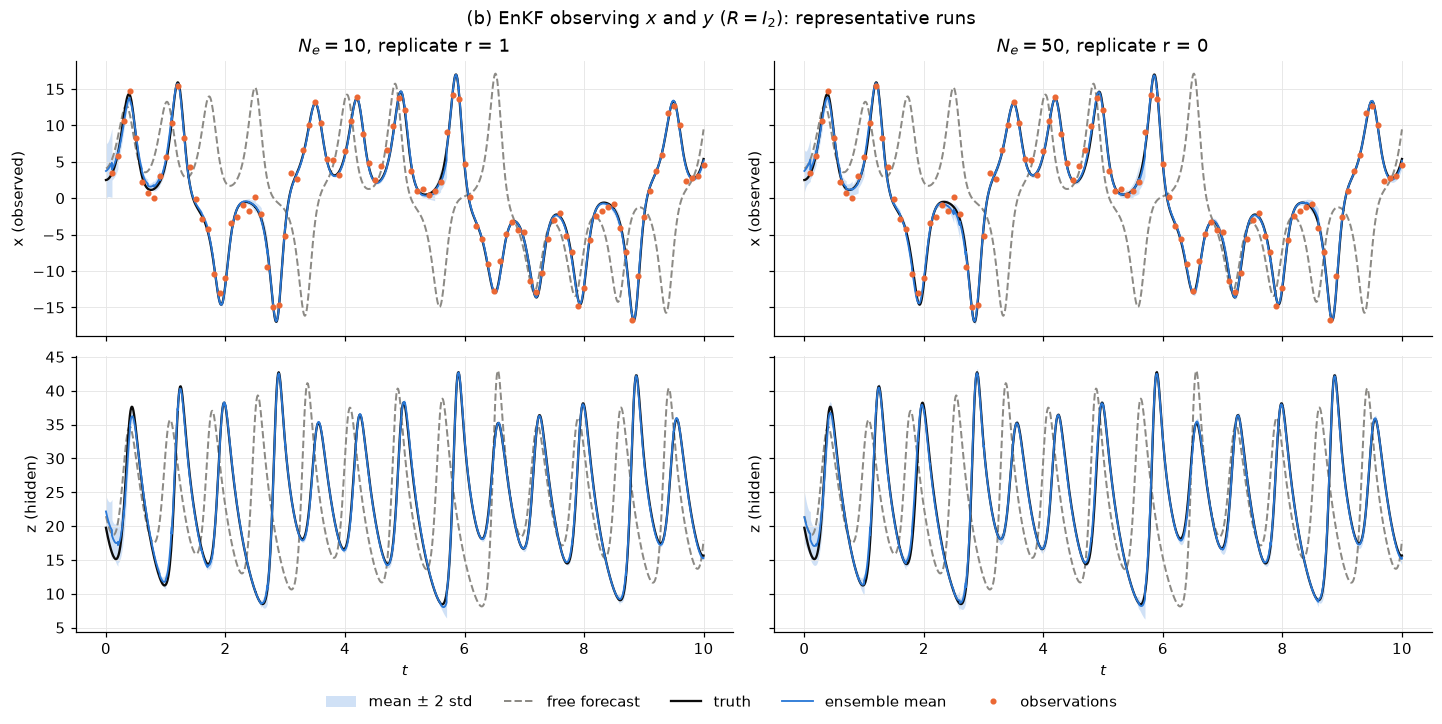

In [6]:
OBS_COORD = 0      # 0 = x, 1 = y

fig, axes = plt.subplots(2, len(ENSEMBLE_SIZES), figsize=(13, 6.5), sharex=True, sharey="row",
                         constrained_layout=True, squeeze=False)
for j, Ne in enumerate(ENSEMBLE_SIZES):
    out = runs[(Ne, rep[Ne])]
    t_m, X_m = flatten(out["seg_mean"], DT_OBS, out["mean_a"][-1])
    _, S_m = flatten(out["seg_std"], DT_OBS, np.sqrt(np.diag(out["cov_a"][-1])))
    for row, i in enumerate([OBS_COORD, 2]):
        ax = axes[row, j]
        ax.fill_between(t_m, X_m[:, i] - 2 * S_m[:, i], X_m[:, i] + 2 * S_m[:, i],
                        color=C["band"], alpha=0.22, lw=0, label=r"mean $\pm$ 2 std")
        ax.plot(t_fr, X_fr[:, i], color=C["free"], ls="--", lw=1.3, label="free forecast")
        ax.plot(t_tr, X_tr[:, i], color=C["truth"], lw=1.5, label="truth")
        ax.plot(t_m, X_m[:, i], color=C["mean"], lw=1.2, label="ensemble mean")
        if i in (0, 1):
            ax.plot(t_obs, Y_part[:, i], "o", ms=3, color=C["obs"], label="observations")
        ax.set_ylabel(labels[i] + (" (observed)" if i in (0, 1) else " (hidden)"))
    axes[0, j].set_title(f"$N_e = {Ne}$, replicate r = {rep[Ne]}")
for ax in axes[-1]:
    ax.set_xlabel("$t$")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=5)
fig.suptitle(r"(b) EnKF observing $x$ and $y$ ($R = I_2$): representative runs")
plt.show()

### RMSE and spread for every replicate

$\mathrm{RMSE}_k$ (solid) and $\mathrm{Spread}_k$ (dashed) at the analysis times $t_0, \dots, t_L$; colors are replicates. The gray line is the RMSE of the free forecast.

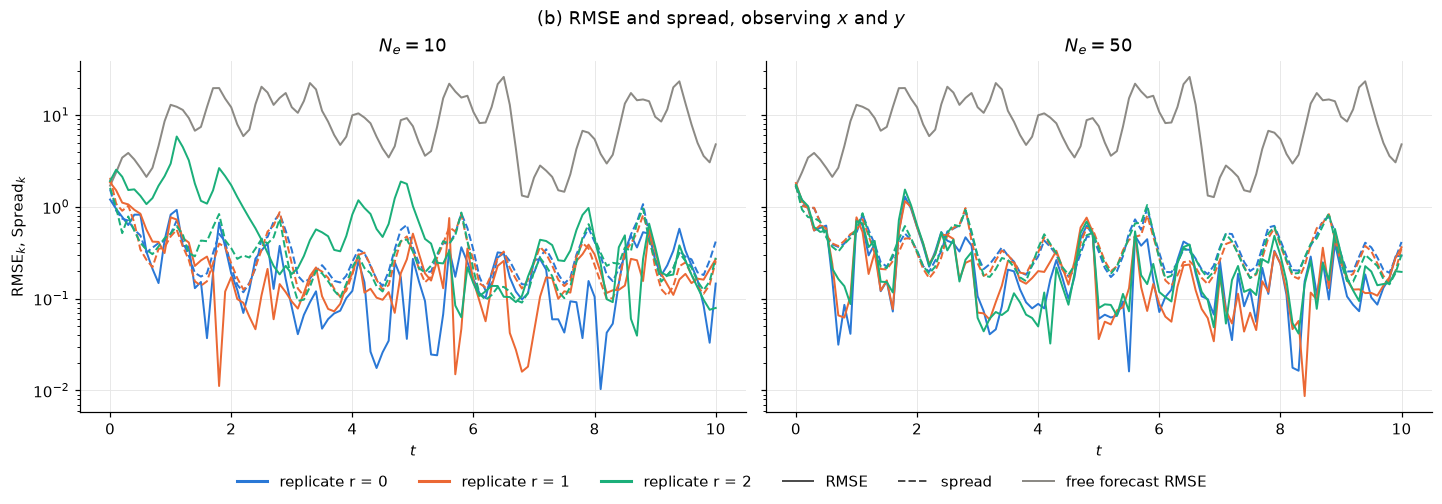

In [7]:
fig, axes = plt.subplots(1, len(ENSEMBLE_SIZES), figsize=(13, 4.5), sharey=True,
                         constrained_layout=True, squeeze=False)
for j, Ne in enumerate(ENSEMBLE_SIZES):
    ax = axes[0, j]
    ax.semilogy(t_an, rmse_free, color=C["free"], lw=1.3)
    for r, color in zip(REPLICATES, REP_COLORS):
        o = runs[(Ne, r)]
        ax.semilogy(t_an, o["rmse"], color=color, lw=1.3)
        ax.semilogy(t_an, o["spread"], color=color, lw=1.3, ls="--")
    ax.set_title(f"$N_e = {Ne}$")
    ax.set_xlabel("$t$")
axes[0, 0].set_ylabel(r"RMSE$_k$, Spread$_k$")
handles = [Line2D([], [], color=c, lw=2, label=f"replicate r = {r}") for r, c in zip(REPLICATES, REP_COLORS)]
handles += [Line2D([], [], color="0.3", lw=1.3, label="RMSE"),
            Line2D([], [], color="0.3", lw=1.3, ls="--", label="spread"),
            Line2D([], [], color=C["free"], lw=1.3, label="free forecast RMSE")]
fig.legend(handles=handles, loc="outside lower center", ncol=6)
fig.suptitle(r"(b) RMSE and spread, observing $x$ and $y$")
plt.show()

**Answer to 3(b).** *Discuss ensemble-size effects and variability across seeds.*

On average, the larger ensembles didn't perform that much better than the smaller ensembles. However, it looks like the variation across seeds was lower for the larger ensembles.



## (c) Observing the full state

$H = I_3$, $R = I_3$, $N_e = 50$, one seed: replicate $r = 0$, so the initial ensemble is identical to the partial-observation run with $N_e = 50$, $r = 0$ (the perturbation draws differ because they now have three components). Same full-state data as in (a).

Left panel: RMSE (solid) and spread (dashed). Other panels: absolute error of the ensemble mean in each component (solid) and that component's ensemble standard deviation (dashed).

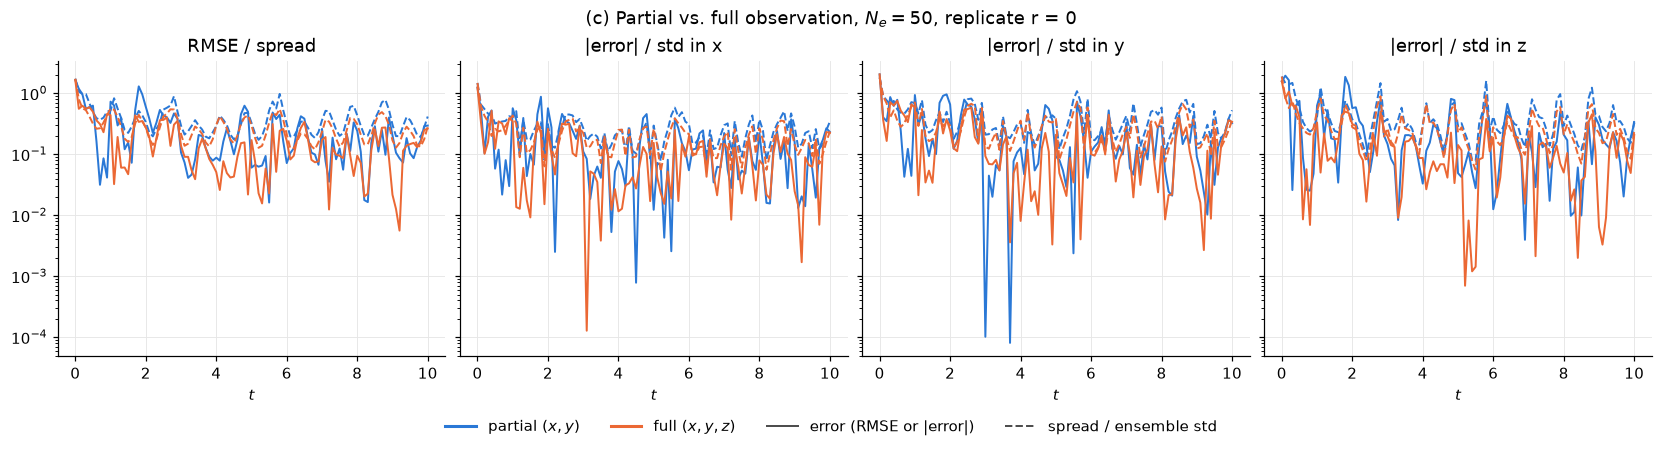

run                   sqrt(mean RMSE^2)  final RMSE   rms err x   rms err y   rms err z  runtime (s)
partial (x, y)                    0.355       0.295       0.226       0.345       0.457        0.100
full (x, y, z)                    0.225       0.263       0.155       0.261       0.244        0.100


In [8]:
NE_FULL, R_FULL = 50, 0
E0 = draw_initial_ensemble(m0, P0, NE_FULL, rng_init(NE_FULL, R_FULL))
full = timed_enkf(propagate_ens, E0, Y_full, np.eye(n), np.eye(n), NE_FULL, R_FULL, REPEATS)
part = runs[(NE_FULL, R_FULL)]
compare = {r"partial ($x, y$)": (part, "#2a78d6"), r"full ($x, y, z$)": (full, "#eb6834")}

fig, axes = plt.subplots(1, 4, figsize=(15, 4), sharey=True, constrained_layout=True)
for label, (o, color) in compare.items():
    axes[0].semilogy(t_an, o["rmse"], color=color, lw=1.3, label=label)
    axes[0].semilogy(t_an, o["spread"], color=color, lw=1.3, ls="--")
    err = np.abs(o["mean_a"] - x_true)
    sd = np.sqrt(np.diagonal(o["cov_a"], axis1=1, axis2=2))
    for i in range(n):
        axes[i + 1].semilogy(t_an, err[:, i], color=color, lw=1.3)
        axes[i + 1].semilogy(t_an, sd[:, i], color=color, lw=1.3, ls="--")
axes[0].set_title("RMSE / spread")
for i in range(n):
    axes[i + 1].set_title(f"|error| / std in {labels[i]}")
for ax in axes:
    ax.set_xlabel("$t$")
handles = [Line2D([], [], color=c, lw=2, label=lab) for lab, (_, c) in compare.items()]
handles += [Line2D([], [], color="0.3", lw=1.3, label="error (RMSE or |error|)"),
            Line2D([], [], color="0.3", lw=1.3, ls="--", label="spread / ensemble std")]
fig.legend(handles=handles, loc="outside lower center", ncol=4)
fig.suptitle(rf"(c) Partial vs. full observation, $N_e = {NE_FULL}$, replicate r = {R_FULL}")
plt.show()

print(f"{'run':<20} {'sqrt(mean RMSE^2)':>18} {'final RMSE':>11}" +
      "".join(f"{'rms err ' + lab:>12}" for lab in labels) + f"{'runtime (s)':>13}")
for label, (o, _) in compare.items():
    err = o["mean_a"][1:] - x_true[1:]
    comp = np.sqrt(np.mean(err ** 2, axis=0))
    plain = label.replace("$", "")
    print(f"{plain:<20} {time_avg_rmse(o['rmse']):>18.3f} {o['rmse'][-1]:>11.3f}" +
          "".join(f"{c:>12.3f}" for c in comp) + f"{o['wall_time']:>13.3f}")

### (c) continued: the third row of $K_{k,e}$ and the innovations (partial observation)

Partial-observation run, $N_e = 50$, $r = 0$. For the analysis at $t_k$ with $k$ = `K_SHOW` (change it to look at another analysis), the cell prints the forecast ensemble's covariance and correlations, the gain $K_{k,e}$ (a $3 \times 2$ matrix), the mean innovation $y_k - H\bar x_k^f$, the third row of $K_{k,e}$ multiplied by each innovation component, and the change in the $z$-component of the ensemble mean, along with a few individual members. The figure shows the same quantities at every analysis time.

In [11]:
K_SHOW = 25          # analysis index k, t_k = k * DT_OBS

o = part
k = K_SHOW
Kk = o["K"][k - 1]                         # (3, 2)
Pf = o["cov_f"][k]
sd_f = np.sqrt(np.diag(Pf))
corr_f = Pf / np.outer(sd_f, sd_f)
d_bar = o["innovation_mean"][k - 1]        # y_k - H xbar_f
D_mem = o["innovations"][k - 1]            # (2, Ne): y_k + v^(i) - H x_f^(i)
zf, za, zt = o["mean_f"][k, 2], o["mean_a"][k, 2], x_true[k, 2]

print(f"analysis k = {k}, t_k = {t_an[k]:.1f}")
print("truth x_k             :", x_true[k])
print("forecast mean xbar_f  :", o["mean_f"][k])
print("analysis mean xbar_a  :", o["mean_a"][k])
print("observation y_k (x, y):", Y_part[k - 1])
print("\nforecast covariance P^f_{k,e}:\n", Pf)
print("forecast correlations:\n", corr_f)
print("\ngain K_{k,e} (rows x, y, z; columns: x-innovation, y-innovation):\n", Kk)
print("third row K_3 =", Kk[2])
print("\nmean innovation y_k - H xbar_f  =", d_bar)
print(f"K_31 * d_x = {Kk[2, 0] * d_bar[0]: .4f}")
print(f"K_32 * d_y = {Kk[2, 1] * d_bar[1]: .4f}")
print(f"sum        = {Kk[2] @ d_bar: .4f}")
print(f"change in z of the ensemble mean, zbar_a - zbar_f = {za - zf: .4f}"
      f"   (= K_3 · mean of the perturbed innovations = {Kk[2] @ D_mem.mean(axis=1): .4f})")
print(f"z error of the mean: forecast {zf - zt: .4f}  ->  analysis {za - zt: .4f}")

print("\nfirst five members:")
print(f"{'i':>3} {'d_x^(i)':>9} {'d_y^(i)':>9} {'K_3 · d^(i)':>12} {'z_f^(i)':>9} {'z_a^(i)':>9}")
for i in range(5):
    d_i = D_mem[:, i]
    print(f"{i:>3} {d_i[0]:>9.3f} {d_i[1]:>9.3f} {Kk[2] @ d_i:>12.3f} "
          f"{o['E_f'][k, 2, i]:>9.3f} {o['E_a'][k, 2, i]:>9.3f}")

analysis k = 25, t_k = 2.5
truth x_k             : [-1.2181 -2.196  10.3058]
forecast mean xbar_f  : [-2.2042 -3.9812 10.5002]
analysis mean xbar_a  : [-1.5708 -2.8459 10.2549]
observation y_k (x, y): [ 0.1964 -2.6954]

forecast covariance P^f_{k,e}:
 [[ 0.3573  0.6405 -0.1384]
 [ 0.6405  1.1482 -0.247 ]
 [-0.1384 -0.247   0.0616]]
forecast correlations:
 [[ 1.      0.9999 -0.9325]
 [ 0.9999  1.     -0.9288]
 [-0.9325 -0.9288  1.    ]]

gain K_{k,e} (rows x, y, z; columns: x-innovation, y-innovation):
 [[ 0.1426  0.2556]
 [ 0.2556  0.4583]
 [-0.0555 -0.0985]]
third row K_3 = [-0.0555 -0.0985]

mean innovation y_k - H xbar_f  = [2.4006 1.2858]
K_31 * d_x = -0.1332
K_32 * d_y = -0.1266
sum        = -0.2598
change in z of the ensemble mean, zbar_a - zbar_f = -0.2453   (= K_3 · mean of the perturbed innovations = -0.2453)
z error of the mean: forecast  0.1944  ->  analysis -0.0509

first five members:
  i   d_x^(i)   d_y^(i)  K_3 · d^(i)   z_f^(i)   z_a^(i)
  0     2.853     0.893       -0

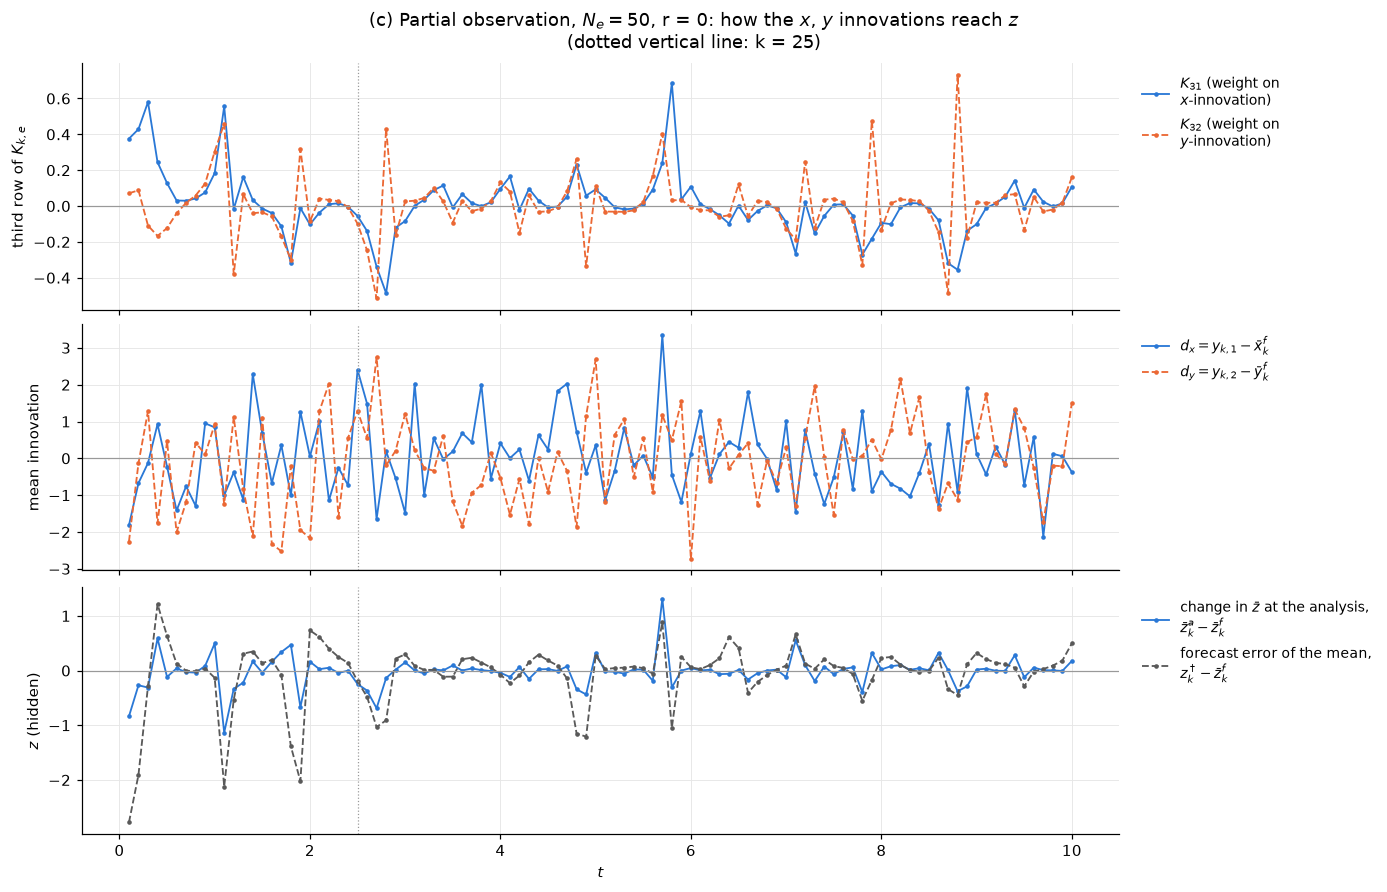

In [10]:
K3 = o["K"][:, 2, :]                       # (L, 2)
d_all = o["innovation_mean"]                # (L, 2)
dz_mean = o["mean_a"][1:, 2] - o["mean_f"][1:, 2]
z_fc_err = x_true[1:, 2] - o["mean_f"][1:, 2]

fig, axes = plt.subplots(3, 1, figsize=(12.5, 8), sharex=True, constrained_layout=True)
axes[0].plot(t_obs, K3[:, 0], ".-", color="#2a78d6", ms=4, label="$K_{31}$ (weight on\n$x$-innovation)")
axes[0].plot(t_obs, K3[:, 1], ".--", color="#eb6834", ms=4, label="$K_{32}$ (weight on\n$y$-innovation)")
axes[0].set_ylabel(r"third row of $K_{k,e}$")
axes[1].plot(t_obs, d_all[:, 0], ".-", color="#2a78d6", ms=4, label=r"$d_x = y_{k,1} - \bar x_k^f$")
axes[1].plot(t_obs, d_all[:, 1], ".--", color="#eb6834", ms=4, label=r"$d_y = y_{k,2} - \bar y_k^f$")
axes[1].set_ylabel("mean innovation")
axes[2].plot(t_obs, dz_mean, ".-", color="#2a78d6", ms=4, label="change in $\\bar z$ at the analysis,\n$\\bar z_k^a - \\bar z_k^f$")
axes[2].plot(t_obs, z_fc_err, ".--", color="0.35", ms=4, label="forecast error of the mean,\n$z_k^\\dagger - \\bar z_k^f$")
axes[2].set_ylabel("$z$ (hidden)")
axes[2].set_xlabel("$t$")
for ax in axes:
    ax.axhline(0, color="0.6", lw=0.8)
    ax.axvline(t_an[K_SHOW], color="0.6", lw=0.8, ls=":")
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=9)
fig.suptitle(rf"(c) Partial observation, $N_e = {NE_FULL}$, r = {R_FULL}: how the $x$, $y$ innovations reach $z$"
             f"\n(dotted vertical line: k = {K_SHOW})")
plt.show()

**Answer to 3(c).** *Compare the full- and partial-observation errors, and use the third row of $K_{k,e}$ and the innovations to explain how observing the first two coordinates updates hidden $z$.*

The model $M$ relates $z$ to $x$ and $y$, and since $P^f$ (which appears in the formula for $K$) is updated through the model, observations in $x$ and $y$ are tied to $z$.



## AI use (draft — edit as needed)

Claude (Anthropic) helped write and debug the code for Problem 3: the `enkf.py` module and the code cells in this notebook. The answers to 3(b) and 3(c) are my own.